# DATA 620 – Web Analytics

**Week Ten/Eleven Assignment: Spam and Non-Spam Email Classification Using the UCI Spambase Dataset**

**Brandon Chanderban**

## 1. Project Overview

For this assignment, the UCI Spambase dataset will be utilized to examine the classification of email messages as spam or non-spam through supervised machine learning techniques. The dataset consists of previously classified email observations represented by numerical features extracted from their contents, including word frequencies and patterns associated with capitalization.

The analysis will involve developing and comparing three classification approaches, namely Decision Tree, Naive Bayes, and Maximum Entropy (implemented through logistic regression). Following the division of the dataset into training, development-test, and test subsets, the classifiers will be evaluated using both the complete feature set and smaller selections of potentially informative features. Furthermore, the analysis will examine the occurrence of classification errors and consider how reducing the number of features may influence predictive performance and computational efficiency.

### 1.1 Research Question

How effectively can supervised machine learning classifiers distinguish spam from non-spam email observations using the numerical features provided within the UCI Spambase dataset, and how does classification performance change when the number of predictor features is reduced?

### 1.2 Research Objectives

1. To examine the composition of the UCI Spambase dataset and the distribution of its spam and non-spam observations.
2. To develop and compare Decision Tree, Naive Bayes, and Maximum Entropy classification models using separate training and development-test datasets.
3. To investigate how reducing the number of predictor features influences classification performance compared with utilizing the complete feature set.
4. To identify and examine the predictor features demonstrating the strongest statistical associations with spam classification, particularly those involving punctuation and capitalization.
5. To evaluate the selected classifier using previously withheld test observations and examine its classification errors, whilst considering the practical implications of feature selection.

## 2. Dataset Description and Acquisition

### 2.1 Dataset Description

The dataset selected for this analysis is Spambase, obtained from the UCI Machine Learning Repository. Originally donated in 1999, the dataset contains 4,601 email observations, each represented by 57 numerical predictor features and a binary classification label indicating whether the email is considered spam (1) or non-spam (0).

The available features represent characteristics extracted from the original email messages, including the frequency of particular words and the occurrence of certain punctuation marks. Additional measurements capture patterns involving consecutive capital letters, which may also provide useful information when distinguishing unsolicited messages from legitimate correspondence.

An important consideration is that the dataset contains previously extracted features rather than the original email text. Consequently, the classification models developed within this assignment will utilize these numerical representations. In a real-world application, comparable features would first need to be extracted from incoming email messages before they could be classified.

### 2.2 Importing the Dataset

In [95]:
# Install the package required to access the UCI repository.
!pip -q install ucimlrepo

# Import the required libraries.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

# Retrieve the UCI Spambase dataset.
spambase = fetch_ucirepo(id=94)

# Separate the predictor features from the classification labels.
X = spambase.data.features.copy()
y = spambase.data.targets.squeeze().copy()

# Display the dimensions of the dataset.
print("Number of email observations:", X.shape[0])
print("Number of predictor features:", X.shape[1])
print("Number of classification categories:", y.nunique())

# Preview the first five observations.
print("\nFirst five observations:")
display(X.head())

# Examine the classification labels.
print("\nDistribution of classification labels:")
display(y.value_counts().sort_index().rename(
    index={0: "Non-spam", 1: "Spam"}
))

Number of email observations: 4601
Number of predictor features: 57
Number of classification categories: 2

First five observations:


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.0,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.0,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.0,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.0,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.0,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191



Distribution of classification labels:


,count
Class,
Non-spam,2788
Spam,1813


## 3. Data Validation and Cleaning

### 3.1 Preliminary Data Validation

An initial examination of the Spambase dataset will be conducted to identify any structural issues that could affect the subsequent classification analyses.

In [96]:
# Examine the structure and data types of the predictor features.
print("Dataset information:")
X.info()

# Check for missing values.
print("\nMissing values in predictor features:",
      X.isnull().sum().sum())

print("Missing values in classification labels:",
      y.isnull().sum())

# Check for duplicated records.
combined_data = X.copy()
combined_data["spam"] = y

print("\nNumber of duplicated records:",
      combined_data.duplicated().sum())

# Confirm the available classification labels.
print("\nUnique classification labels:")
print(sorted(y.unique()))

# Examine descriptive statistics for the predictor features.
print("\nDescriptive statistics:")
display(X.describe().round(2))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 57 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4601 non-null   float64
 13  word_freq_re

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total
count,4601.00,4601.00,4601.00,4601.00,4601.00,4601.00,4601.00,4601.00,4601.00,4601.00,...,4601.00,4601.00,4601.00,4601.00,4601.00,4601.00,4601.00,4601.00,4601.00,4601.00
mean,0.10,0.21,0.28,0.07,0.31,0.10,0.11,0.11,0.09,0.24,...,0.03,0.04,0.14,0.02,0.27,0.08,0.04,5.19,52.17,283.29
std,0.31,1.29,0.50,1.40,0.67,0.27,0.39,0.40,0.28,0.64,...,0.29,0.24,0.27,0.11,0.82,0.25,0.43,31.73,194.89,606.35
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00
25%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.59,6.00,35.00
50%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.06,0.00,0.00,0.00,0.00,2.28,15.00,95.00
75%,0.00,0.00,0.42,0.00,0.38,0.00,0.00,0.00,0.00,0.16,...,0.00,0.00,0.19,0.00,0.32,0.05,0.00,3.71,43.00,266.00
max,4.54,14.28,5.10,42.81,10.00,5.88,7.27,11.11,5.26,18.18,...,10.00,4.38,9.75,4.08,32.48,6.00,19.83,1102.50,9989.00,15841.00


### 3.2 Duplicate Record Examination

Given that the previous check for duplicate records returned a figure of 391, this next analysis will examine the observations themselves to determine whether identical feature profiles share the same classification labels, thereby informing how these records should be handled before partitioning the dataset.

In [97]:
# Identify records duplicated across both predictors and labels.
exact_duplicates = combined_data.duplicated().sum()

# Identify repeated predictor profiles, regardless of classification.
duplicate_features = X.duplicated(keep=False)

# Determine whether identical predictor profiles have conflicting labels.
conflicting_labels = (
    combined_data.groupby(list(X.columns))["spam"]
    .nunique()
    .gt(1)
    .sum()
)

print("Exact duplicate records:", exact_duplicates)

print("Observations sharing repeated feature profiles:",
      duplicate_features.sum())

print("Feature profiles associated with conflicting labels:",
      conflicting_labels)

# Calculate the number of records remaining if exact duplicates are removed.
print("\nObservations after removing exact duplicates:",
      len(combined_data.drop_duplicates()))

Exact duplicate records: 391
Observations sharing repeated feature profiles: 577
Feature profiles associated with conflicting labels: 3

Observations after removing exact duplicates: 4210


The examination identified 391 exact duplicate records, whilst 577 observations shared repeated feature profiles. Furthermore, three distinct feature profiles were associated with conflicting classification labels.

Given the potential for duplicated observations to influence model evaluation, the exact duplicates will be removed before partitioning the dataset. However, identical numerical features do not necessarily indicate that the original email messages were identical. The remaining conflicting-label profiles will therefore be considered when preparing the training and testing subsets.

### 3.3 Removing Exact Duplicate Records

The 391 exact duplicate records will now be removed to reduce the possibility of repeated observations influencing the subsequent classification results.

In [98]:
# Remove exact duplicates, considering both the features and class labels.
cleaned_data = combined_data.drop_duplicates().reset_index(drop=True)

# Update the predictor features and classification labels.
X = cleaned_data.drop(columns="spam")
y = cleaned_data["spam"]

# Confirm the results of duplicate removal.
print("Original number of observations:", len(combined_data))
print("Number of exact duplicates removed:",
      len(combined_data) - len(cleaned_data))
print("Number of observations remaining:", len(cleaned_data))

print("\nExact duplicates remaining:",
      cleaned_data.duplicated().sum())

print("\nUpdated classification distribution:")
display(y.value_counts().sort_index().rename(
    index={0: "Non-spam", 1: "Spam"}
))

Original number of observations: 4601
Number of exact duplicates removed: 391
Number of observations remaining: 4210

Exact duplicates remaining: 0

Updated classification distribution:


,count
spam,
Non-spam,2531
Spam,1679


**Findings:**

Following the removal of 391 exact duplicate records, the dataset was reduced from 4,601 to 4,210 observations, comprising 2,531 non-spam and 1,679 spam records. The cleaned dataset will be utilized for the subsequent classification analysis, with additional care taken to prevent identical feature profiles from appearing across different data partitions.

## 4. Exploratory Data Analysis



### 4.1 Distribution of Spam and Non-Spam Observations

The following visualization will examine the distribution of spam and non-spam observations within the cleaned dataset to establish whether the classification categories are represented equally.

Classification distribution before and after cleaning:


,Before Cleaning (Count),Before Cleaning (%),After Cleaning (Count),After Cleaning (%)
Non-spam,2788,60.6,2531,60.12
Spam,1813,39.4,1679,39.88


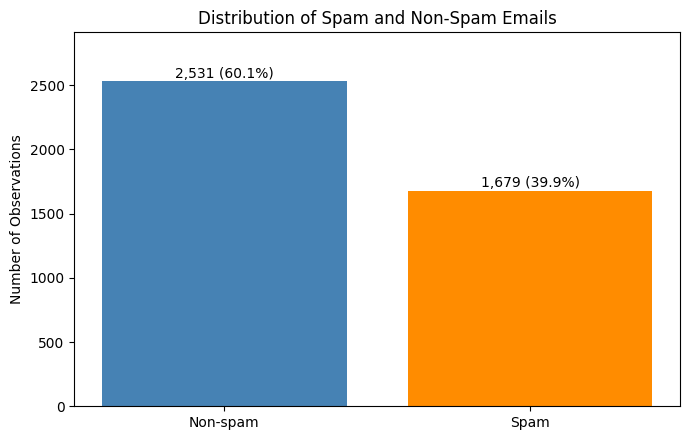

In [99]:
# Calculate the classification counts before and after cleaning.
before_counts = combined_data["spam"].value_counts().sort_index()
after_counts = cleaned_data["spam"].value_counts().sort_index()

# Calculate the percentage represented by each classification.
before_percentages = before_counts / before_counts.sum() * 100
after_percentages = after_counts / after_counts.sum() * 100

# Compare the classification distributions before and after cleaning.
class_comparison = pd.DataFrame({
    "Before Cleaning (Count)": before_counts,
    "Before Cleaning (%)": before_percentages.round(2),
    "After Cleaning (Count)": after_counts,
    "After Cleaning (%)": after_percentages.round(2)
})

class_comparison.index = ["Non-spam", "Spam"]

print("Classification distribution before and after cleaning:")
display(class_comparison)

# Visualize the classification distribution after cleaning.
labels = ["Non-spam", "Spam"]
counts = after_counts.values

plt.figure(figsize=(7, 4.5))
bars = plt.bar(labels, counts, color=["steelblue", "darkorange"])

# Display the count and percentage above each bar.
for bar, count, percentage in zip(
    bars, counts, after_percentages.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 25,
        f"{count:,} ({percentage:.1f}%)",
        ha="center"
    )

print()
plt.title("Distribution of Spam and Non-Spam Emails")
plt.ylabel("Number of Observations")
plt.ylim(0, max(counts) * 1.15)
plt.tight_layout()
plt.show()

The classification distribution indicates that non-spam observations accounted for approximately 60.60% of the original dataset, compared with 39.40% classified as spam. Following the removal of duplicate records, these proportions changed slightly to 60.12% and 39.88%, respectively.

Although the cleaning process reduced the total number of observations, the relative distribution of the two categories remained largely unchanged. Given the greater representation of non-spam observations, classification accuracy alone may not fully reflect the effectiveness of the resulting models. Consequently, additional performance measures will be considered when evaluating their ability to distinguish between the two categories.

### 4.2 Comparing Feature Characteristics

The following analysis will examine whether selected email characteristics exhibit differences between spam and non-spam observations, with particular consideration given to exclamation-mark frequency and capitalization patterns.

In [100]:
# Select the features for examining punctuation and capitalization patterns.
selected_features = [
    "char_freq_!",
    "capital_run_length_average"
]

# Calculate descriptive statistics for each classification.
feature_comparison = (
    cleaned_data.groupby("spam")[selected_features]
    .agg(["mean", "median", "std"])
    .round(3)
)

# Rename the classification labels for readability.
feature_comparison.index = feature_comparison.index.map({
    0: "Non-spam",
    1: "Spam"
})

print("Comparison of selected features by email classification:")
display(feature_comparison)

Comparison of selected features by email classification:


char_freq_!               capital_run_length_average               
                mean median    std                       mean median     std
spam                                                                        
Non-spam       0.121  0.000  0.861                      2.407  1.909   5.291
Spam           0.523  0.334  0.755                      9.871  3.564  51.772

The results indicate that spam observations exhibit higher average exclamation-mark frequencies (0.523 versus 0.121) and longer consecutive capital-letter sequences (9.871 versus 2.407) than non-spam observations. However, the substantial variability in capitalization amongst spam emails suggests that these characteristics may differ considerably across observations. Both features therefore appear potentially useful for classification and will be examined further during model development.

### 4.3 Visualizing Exclamation-Mark Frequency

Subsequently, the average exclamation-mark frequency for each classification will be visualized.

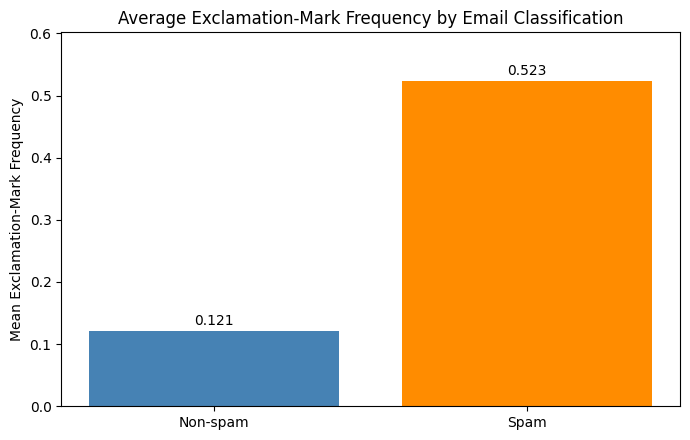

In [101]:
# Calculate the mean exclamation-mark frequency by classification.
exclamation_means = (
    cleaned_data.groupby("spam")["char_freq_!"]
    .mean()
    .reindex([0, 1])
)

# Create a bar chart comparing the classification groups.
plt.figure(figsize=(7, 4.5))

bars = plt.bar(
    ["Non-spam", "Spam"],
    exclamation_means.values,
    color=["steelblue", "darkorange"]
)

# Display the average frequency above each bar.
for bar, value in zip(bars, exclamation_means.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(exclamation_means) * 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.title("Average Exclamation-Mark Frequency by Email Classification")
plt.ylabel("Mean Exclamation-Mark Frequency")
plt.ylim(0, max(exclamation_means) * 1.15)
plt.tight_layout()
plt.show()

### 4.4 Visualizing Capitalization Patterns

Next, an examination of the average length of consecutive capital-letter sequences will be conducted.

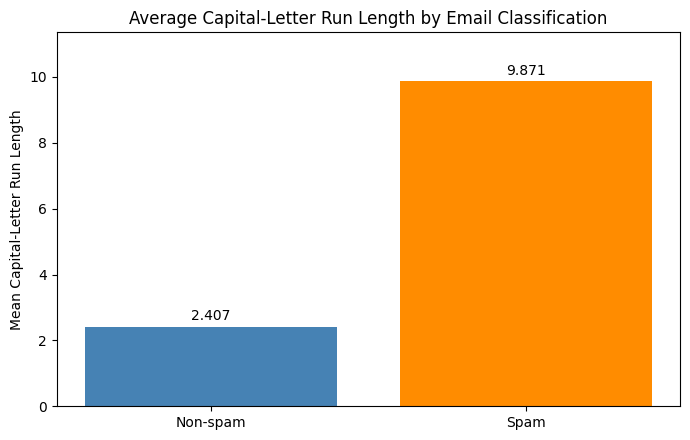

In [102]:
# Calculate the mean length of consecutive capital-letter runs.
capital_means = (
    cleaned_data.groupby("spam")["capital_run_length_average"]
    .mean()
    .reindex([0, 1])
)

# Create a bar chart comparing the classification groups.
plt.figure(figsize=(7, 4.5))

bars = plt.bar(
    ["Non-spam", "Spam"],
    capital_means.values,
    color=["steelblue", "darkorange"]
)

# Display the average values above each bar.
for bar, value in zip(bars, capital_means.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(capital_means) * 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.title("Average Capital-Letter Run Length by Email Classification")
plt.ylabel("Mean Capital-Letter Run Length")
plt.ylim(0, max(capital_means) * 1.15)
plt.tight_layout()
plt.show()

## 5. Data Partitioning

Prior to developing the classification models, the cleaned dataset will be divided into separate training, development-test, and final test subsets. Approximately 70% of the observations will be allocated to training, whilst the remaining 30% will be divided equally between development-testing and final testing.

The training subset will be utilized to develop the classifiers, with the development-test subset subsequently used to compare their performance and evaluate different feature selections. The final test subset will remain separate until a preferred classifier has been identified, thereby providing an independent assessment of its ability to classify previously unseen observations.

Furthermore, given the presence of several identical feature profiles with conflicting classification labels, a group-aware partitioning approach will be employed to prevent observations sharing the same predictor values from appearing across different subsets.

### 5.1 Creating the Data Partitions

In [103]:
# Import the required data partitioning method.
from sklearn.model_selection import GroupShuffleSplit

# Assign the same group identifier to identical feature profiles.
groups = pd.factorize(
    pd.MultiIndex.from_frame(X),
    sort=False
)[0]

# First split: approximately 70% training and 30% temporary data.
split_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=6767
)

train_idx, temp_idx = next(
    split_1.split(X, y, groups=groups)
)

# Second split: divide the temporary data into development and test sets.
split_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=6767
)

dev_relative_idx, test_relative_idx = next(
    split_2.split(
        X.iloc[temp_idx],
        y.iloc[temp_idx],
        groups=groups[temp_idx]
    )
)

# Convert the temporary indices back to the original dataset positions.
dev_idx = temp_idx[dev_relative_idx]
test_idx = temp_idx[test_relative_idx]

# Create the predictor subsets.
X_train = X.iloc[train_idx].copy()
X_dev = X.iloc[dev_idx].copy()
X_test = X.iloc[test_idx].copy()

# Create the corresponding classification labels.
y_train = y.iloc[train_idx].copy()
y_dev = y.iloc[dev_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Partitioning of Data Executed Successfully.")

Partitioning of Data Executed Successfully.


### 5.2 Examining the Partition Sizes and Class Distribution

The number of observations allocated to each subset will now be verified, alongside the proportions of spam and non-spam observations within each partition.

In [104]:
# Combine the subset labels for comparison.
partitions = {
    "Training": y_train,
    "Development-Test": y_dev,
    "Final Test": y_test
}

# Summarize the number of observations and class proportions.
partition_summary = []

for name, labels in partitions.items():
    counts = labels.value_counts().reindex([0, 1], fill_value=0)

    partition_summary.append({
        "Subset": name,
        "Observations": len(labels),
        "Dataset (%)": round(len(labels) / len(y) * 100, 2),
        "Non-spam": counts[0],
        "Non-spam (%)": round(counts[0] / len(labels) * 100, 2),
        "Spam": counts[1],
        "Spam (%)": round(counts[1] / len(labels) * 100, 2)
    })

partition_summary = pd.DataFrame(partition_summary)

print("Distribution of observations across the data partitions:")
display(partition_summary)

print("Total observations across all subsets:",
      partition_summary["Observations"].sum())

print("Original cleaned dataset observations:", len(X))

Distribution of observations across the data partitions:


,Subset,Observations,Dataset (%),Non-spam,Non-spam (%),Spam,Spam (%)
0,Training,2946,69.98,1767,59.98,1179,40.02
1,Development-Test,632,15.01,376,59.49,256,40.51
2,Final Test,632,15.01,388,61.39,244,38.61


Total observations across all subsets: 4210
Original cleaned dataset observations: 4210


The cleaned dataset was successfully divided into 2,946 training observations (69.98%), 632 development-test observations (15.01%), and 632 final test observations (15.01%). Furthermore, the proportion of spam observations remained relatively consistent across the three subsets, ranging from 38.61% to 40.51%. This distribution provides a suitable foundation for developing and comparing the classification models, whilst reserving the final test subset for independent evaluation.

### 5.3 Verifying the Independence of the Data Partitions

To verify the independence of the partitions, the following checks will determine whether any observations share identical feature profiles across the training, development-test, or final test subsets.

In [105]:
# Retrieve the feature-profile group identifiers for each subset.
train_groups = set(groups[train_idx])
dev_groups = set(groups[dev_idx])
test_groups = set(groups[test_idx])

# Check for shared feature profiles across subsets.
train_dev_overlap = len(train_groups.intersection(dev_groups))
train_test_overlap = len(train_groups.intersection(test_groups))
dev_test_overlap = len(dev_groups.intersection(test_groups))

print("Shared feature profiles between training and development:",
      train_dev_overlap)

print("Shared feature profiles between training and final test:",
      train_test_overlap)

print("Shared feature profiles between development and final test:",
      dev_test_overlap)

# Verify that all observations were assigned exactly once.
all_indices = np.concatenate([train_idx, dev_idx, test_idx])

print("\nTotal assigned observations:", len(all_indices))
print("Unique assigned observations:", len(np.unique(all_indices)))
print("Original cleaned observations:", len(X))

# Verify that all class labels are represented in each subset.
assert all(
    set(labels.unique()) == {0, 1}
    for labels in [y_train, y_dev, y_test]
), "One or more subsets are missing a classification category."

# Confirm that no feature profiles appear across multiple subsets.
assert train_dev_overlap == 0
assert train_test_overlap == 0
assert dev_test_overlap == 0

# Confirm that every observation was assigned exactly once.
assert len(all_indices) == len(X)
assert len(np.unique(all_indices)) == len(X)

print("\nAll partition integrity checks passed.")

Shared feature profiles between training and development: 0
Shared feature profiles between training and final test: 0
Shared feature profiles between development and final test: 0

Total assigned observations: 4210
Unique assigned observations: 4210
Original cleaned observations: 4210

All partition integrity checks passed.


The verification confirmed that no identical feature profiles were shared between the training, development-test, and final test subsets. Furthermore, all 4,210 observations were successfully assigned without duplication or omission. These findings confirm that the partitioning process was completed as intended, reducing the possibility of repeated feature profiles influencing subsequent model evaluations.

## 6. Baseline Classification

Before developing the classification models, a baseline will be established using the most frequently occurring classification within the training dataset. This approach assigns every observation to the majority class, without considering the numerical features associated with individual emails.

Although relatively simplistic, the baseline provides a useful reference for evaluating whether the subsequent classification algorithms offer meaningful improvements in distinguishing spam from non-spam observations.

### 6.1 Developing and Evaluating the Baseline Classifier

The following code shall identify the majority classification from the training data and evaluate its predictive performance on the development-test subset.

In [106]:
# Import the baseline classifier and evaluation metrics.
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Initialize a classifier that always predicts the majority class.
baseline_model = DummyClassifier(strategy="most_frequent")

# Train the baseline classifier using the training subset.
baseline_model.fit(X_train, y_train)

# Generate predictions for the development-test subset.
baseline_predictions = baseline_model.predict(X_dev)

# Calculate the classification performance measures.
baseline_accuracy = accuracy_score(y_dev, baseline_predictions)
baseline_precision = precision_score(
    y_dev, baseline_predictions, zero_division=0
)
baseline_recall = recall_score(
    y_dev, baseline_predictions, zero_division=0
)
baseline_f1 = f1_score(
    y_dev, baseline_predictions, zero_division=0
)

# Display the majority class identified during training.
majority_class = y_train.value_counts().idxmax()

print("Majority classification:",
      "Spam" if majority_class == 1 else "Non-spam")

# Summarize baseline classification performance.
baseline_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score (%)": [
        baseline_accuracy * 100,
        baseline_precision * 100,
        baseline_recall * 100,
        baseline_f1 * 100
    ]
})

print("\nBaseline classification performance:")
display(baseline_results.round(2))

# Examine the number of correct and incorrect predictions.
baseline_correct = (baseline_predictions == y_dev).sum()
baseline_incorrect = (baseline_predictions != y_dev).sum()

print("\nCorrect classifications:", baseline_correct)
print("Incorrect classifications:", baseline_incorrect)

# Display the confusion matrix.
baseline_cm = confusion_matrix(
    y_dev, baseline_predictions, labels=[0, 1]
)

baseline_cm_table = pd.DataFrame(
    baseline_cm,
    index=["Actual Non-spam", "Actual Spam"],
    columns=["Predicted Non-spam", "Predicted Spam"]
)

print("\nBaseline confusion matrix:")
display(baseline_cm_table)

Majority classification: Non-spam

Baseline classification performance:


,Metric,Score (%)
0,Accuracy,59.49
1,Precision,0.00
2,Recall,0.00
3,F1-Score,0.00



Correct classifications: 376
Incorrect classifications: 256

Baseline confusion matrix:


,Predicted Non-spam,Predicted Spam
Actual Non-spam,376,0
Actual Spam,256,0


**Findings:**

The baseline classifier identified non-spam as the majority category and consequently assigned all 632 development-test observations to this classification. This resulted in an accuracy of 59.49%, with 376 observations classified correctly and the remaining 256 incorrectly identified as non-spam.

However, the model failed to identify any actual spam observations, resulting in a spam recall and F1-score of 0%. These findings demonstrate the limitations of relying solely on the majority classification and establish a benchmark against which the subsequent models can be evaluated.

## 7. Development and Comparison of Classification Models

Following the establishment of the baseline, three supervised classification approaches will be examined: Decision Tree, Naive Bayes, and Maximum Entropy, the latter implemented through logistic regression. These approaches differ in how they learn relationships between the predictor features and their corresponding classification labels.

Each model will initially be trained using all 57 available predictors and evaluated against the same development-test subset. Their performance will be compared to determine whether the classification methods provide meaningful improvements over the majority-class baseline.

The final test subset will remain withheld during this stage, with model selection and subsequent feature comparisons conducted using the development-test results.

### 7.1 Training the Three Classification Models

Each classifier will be trained using the complete feature set, subsequently evaluating its ability to identify spam and non-spam observations. Training and prediction times will also be recorded to provide an initial indication of computational requirements.

In [107]:
# Import the classification algorithms and preprocessing tools.
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from time import perf_counter

# Define the three classification approaches.
models = {
    "Decision Tree": DecisionTreeClassifier(
        min_samples_leaf=5,
        random_state=6767
    ),
    "Naive Bayes": GaussianNB(),
    "Maximum Entropy": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=5000,
            random_state=6767
        )
    )
}

# Store the results and predictions for later comparisons.
model_results = []
model_predictions = {}

# Train and evaluate each classifier.
for name, model in models.items():

    # Record the time required to train the model.
    start_time = perf_counter()
    model.fit(X_train, y_train)
    training_time = perf_counter() - start_time

    # Generate predictions using the development-test subset.
    start_time = perf_counter()
    predictions = model.predict(X_dev)
    prediction_time = perf_counter() - start_time

    # Save the predictions for further examination.
    model_predictions[name] = predictions

    # Calculate the classification performance measures.
    model_results.append({
        "Classifier": name,
        "Features": X_train.shape[1],
        "Accuracy (%)": accuracy_score(
            y_dev, predictions
        ) * 100,
        "Precision (%)": precision_score(
            y_dev, predictions, zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_dev, predictions, zero_division=0
        ) * 100,
        "F1-Score (%)": f1_score(
            y_dev, predictions, zero_division=0
        ) * 100,
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

    print(f"{name} training and evaluation completed.")

# Convert the results to a DataFrame.
model_results = pd.DataFrame(model_results)

print("\nClassification performance using all 57 features:")
display(model_results.round(3))

Decision Tree training and evaluation completed.
Naive Bayes training and evaluation completed.
Maximum Entropy training and evaluation completed.

Classification performance using all 57 features:


,Classifier,Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Training Time (s),Prediction Time (s)
0,Decision Tree,57,88.608,87.705,83.594,85.600,0.062,0.002
1,Naive Bayes,57,85.285,74.474,96.875,84.211,0.005,0.002
2,Maximum Entropy,57,91.772,92.500,86.719,89.516,0.026,0.003


### 7.2 Comparing the Classifiers Against the Baseline

The development-test results from the three trained classifiers will be compared against the majority-class baseline to determine the extent to which each approach improves classification performance.

In [108]:
# Create a baseline record using the previously calculated scores.
baseline_comparison = pd.DataFrame([{
    "Classifier": "Majority-Class Baseline",
    "Features": 0,
    "Accuracy (%)": baseline_accuracy * 100,
    "Precision (%)": baseline_precision * 100,
    "Recall (%)": baseline_recall * 100,
    "F1-Score (%)": baseline_f1 * 100
}])

# Select the corresponding evaluation measures from the trained models.
trained_comparison = model_results[[
    "Classifier",
    "Features",
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]]

# Combine the baseline and model results.
classification_comparison = pd.concat(
    [baseline_comparison, trained_comparison],
    ignore_index=True
)

# Calculate the improvement in accuracy over the baseline.
classification_comparison["Accuracy Improvement (pp)"] = (
    classification_comparison["Accuracy (%)"]
    - baseline_accuracy * 100
)

print("Development-test classification comparison:")
display(classification_comparison.round(2))

Development-test classification comparison:


,Classifier,Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Accuracy Improvement (pp)
0,Majority-Class Baseline,0,59.49,0.00,0.00,0.00,0.00
1,Decision Tree,57,88.61,87.70,83.59,85.60,29.11
2,Naive Bayes,57,85.28,74.47,96.88,84.21,25.79
3,Maximum Entropy,57,91.77,92.50,86.72,89.52,32.28


**Interpretation:**

All three classification models substantially outperformed the majority-class baseline of 59.49% accuracy. Maximum Entropy achieved the highest accuracy (91.77%) and F1-score (89.52%), representing an improvement of 32.28 percentage points over the baseline. Decision Tree also performed strongly, attaining 88.61% accuracy, followed by Naive Bayes at 85.28%. These findings demonstrate that the supervised classification approaches were considerably more effective than simply predicting the majority class.

### 7.3 Examining Classification Errors

We will now examine the classification errors made by each model, particularly instances where legitimate emails were incorrectly identified as spam or spam emails were mistakenly classified as non-spam.

In [109]:
# Examine correct classifications and error types for each model.
error_results = []

for name, predictions in model_predictions.items():

    # Extract the values from the confusion matrix.
    tn, fp, fn, tp = confusion_matrix(
        y_dev, predictions, labels=[0, 1]
    ).ravel()

    error_results.append({
        "Classifier": name,
        "Correct": tn + tp,
        "Incorrect": fp + fn,
        "False Positives": fp,
        "False Negatives": fn
    })

# Display the classification error comparison.
error_comparison = pd.DataFrame(error_results)

print("Classification errors on the development-test subset:")
display(error_comparison)

Classification errors on the development-test subset:


,Classifier,Correct,Incorrect,False Positives,False Negatives
0,Decision Tree,560,72,30,42
1,Naive Bayes,539,93,85,8
2,Maximum Entropy,580,52,18,34


**Interpretation:**

An examination of the classification errors revealed notable differences between the three approaches. Maximum Entropy recorded the fewest false positives (18), compared with 30 for Decision Tree and 85 for Naive Bayes. Conversely, Naive Bayes demonstrated the highest spam recall (96.88%), overlooking only eight actual spam observations, compared with 34 for Maximum Entropy and 42 for Decision Tree.

These findings highlight the tradeoff between minimizing the incorrect classification of legitimate emails and identifying the greatest possible proportion of spam. Whilst Maximum Entropy produced fewer classification errors, Naive Bayes may be preferable when prioritizing spam detection. Both models will therefore remain under consideration during the subsequent feature-selection analysis.

## 8. Feature Selection and Reduced-Feature Examination

Having evaluated the three classification approaches using all 57 predictor features, the next stage will investigate whether smaller selections of features can achieve comparable classification performance. An important consideration is whether utilizing fewer predictors can reduce computational requirements without substantially compromising the accuracy of the resulting models.

For this analysis, feature subsets containing 15 and 10 predictors will be developed and compared against the complete feature set. The selection process will utilize the training observations exclusively, whilst the development-test subset will be retained for evaluating the resulting models. Particular attention will be given to determining whether the reduced feature sets influence the classifiers' ability to identify spam accurately.

### 8.1 Identifying the Most Informative Features

We will now calculate the mutual information scores using the training subset to identify which predictor features are most informative about the spam and non-spam classifications.

In [110]:
# Import the feature-selection method.
from sklearn.feature_selection import mutual_info_classif

# Calculate mutual information scores using training observations only.
feature_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=6767
)

# Rank the features according to their mutual information scores.
feature_ranking = pd.DataFrame({
    "Feature": X_train.columns,
    "Mutual Information": feature_scores
}).sort_values(
    "Mutual Information",
    ascending=False
).reset_index(drop=True)

# Identify the 15 and 10 highest-ranked features.
top_15_features = feature_ranking["Feature"].head(15).tolist()
top_10_features = feature_ranking["Feature"].head(10).tolist()

# Display the selected features and their scores.
print("Top 15 features based on mutual information:")
display(feature_ranking.head(15).round(4))

# Verify that the selected feature sets are nested.
print("\nNumber of features in the larger subset:",
      len(top_15_features))

print("Number of features in the smaller subset:",
      len(top_10_features))

print("Are the top 10 features included within the top 15?",
      set(top_10_features).issubset(set(top_15_features)))

Top 15 features based on mutual information:


,Feature,Mutual Information
0,char_freq_!,0.1779
1,char_freq_$,0.1743
2,capital_run_length_longest,0.1657
3,word_freq_remove,0.1569
4,capital_run_length_average,0.1366
5,word_freq_free,0.1230
6,word_freq_your,0.1199
7,word_freq_hp,0.1168
8,word_freq_000,0.1046
9,word_freq_money,0.1000



Number of features in the larger subset: 15
Number of features in the smaller subset: 10
Are the top 10 features included within the top 15? True


### 8.2 Visualizing the Most Informative Features

The following visualization will display the 15 highest-ranked features according to their mutual information scores, allowing their relative informativeness to be examined.

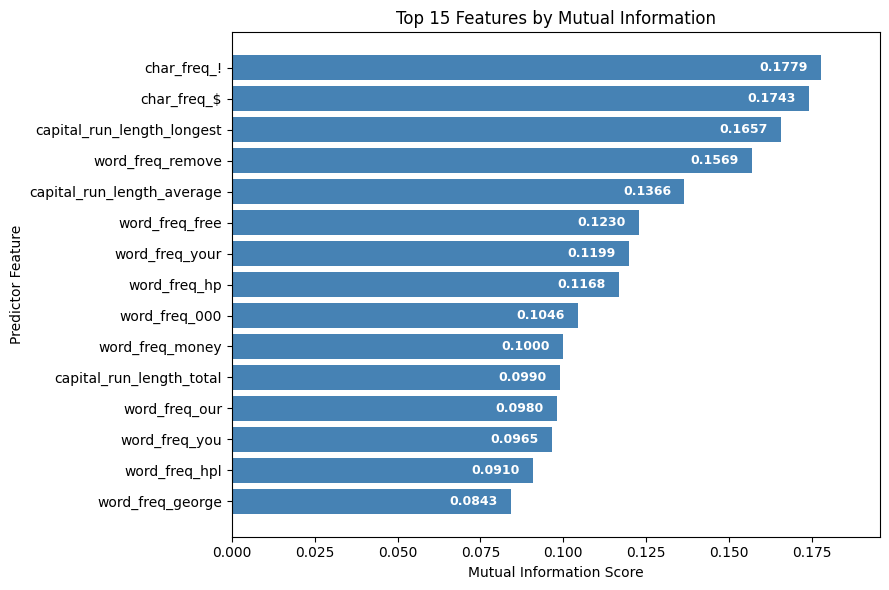

In [111]:
# Select the 15 highest-ranked features for visualization.
top_features_plot = feature_ranking.head(15).sort_values(
    "Mutual Information"
)

# Create a horizontal bar chart.
plt.figure(figsize=(9, 6))

bars = plt.barh(
    top_features_plot["Feature"],
    top_features_plot["Mutual Information"],
    color="steelblue"
)

# Display the mutual information scores inside each bar.
for bar, score in zip(
    bars, top_features_plot["Mutual Information"]
):
    plt.text(
        bar.get_width() - 0.004,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.4f}",
        ha="right",
        va="center",
        color="white",
        fontweight="bold",
        fontsize=9
    )

plt.title("Top 15 Features by Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Predictor Feature")
plt.xlim(0, top_features_plot["Mutual Information"].max() * 1.10)
plt.tight_layout()
plt.show()

**Findings**

The mutual information analysis identified exclamation-mark frequency (0.1779) and dollar-sign frequency (0.1743) as the two highest-ranked predictors, followed by the longest consecutive capital-letter sequence (0.1657). Several word-frequency features, including "remove" and "free", also ranked amongst the most informative. These findings suggest that punctuation and capitalization characteristics may contribute meaningfully to distinguishing spam from non-spam observations. The selected 15-feature and 10-feature subsets will subsequently be evaluated to determine whether they can achieve comparable classification performance to the complete feature set.

The prominence of exclamation-mark frequency may reflect the use of attention-grabbing or promotional language in spam messages, whilst capitalization patterns may similarly indicate attempts to emphasize particular words or phrases. However, these characteristics are not exclusive to spam and should therefore be considered alongside other predictive features.

### 8.3 Training the Classifiers Using Reduced Feature Sets

We can now retrain the three classification models using the selected feature subsets, allowing their performance to be compared with the original 57-feature models.

In [112]:
# Import the function used to create fresh copies of the classifiers.
from sklearn.base import clone

# Define the reduced feature sets.
feature_sets = {
    "15 Features": top_15_features,
    "10 Features": top_10_features
}

# Store the results from the reduced-feature models.
reduced_results = []
reduced_predictions = {}

# Evaluate each classifier using both reduced feature sets.
for set_name, selected_columns in feature_sets.items():

    X_train_selected = X_train[selected_columns]
    X_dev_selected = X_dev[selected_columns]

    for name, original_model in models.items():

        # Create a fresh classifier using the original settings.
        model = clone(original_model)

        # Train the classifier and record the training time.
        start_time = perf_counter()
        model.fit(X_train_selected, y_train)
        training_time = perf_counter() - start_time

        # Generate development-test predictions.
        start_time = perf_counter()
        predictions = model.predict(X_dev_selected)
        prediction_time = perf_counter() - start_time

        # Save the predictions for subsequent analysis.
        reduced_predictions[(set_name, name)] = predictions

        # Calculate the classification errors.
        tn, fp, fn, tp = confusion_matrix(
            y_dev, predictions, labels=[0, 1]
        ).ravel()

        # Store the model performance measures.
        reduced_results.append({
            "Classifier": name,
            "Feature Set": set_name,
            "Features": len(selected_columns),
            "Accuracy (%)": accuracy_score(
                y_dev, predictions
            ) * 100,
            "Precision (%)": precision_score(
                y_dev, predictions, zero_division=0
            ) * 100,
            "Recall (%)": recall_score(
                y_dev, predictions, zero_division=0
            ) * 100,
            "F1-Score (%)": f1_score(
                y_dev, predictions, zero_division=0
            ) * 100,
            "False Positives": fp,
            "False Negatives": fn,
            "Training Time (s)": training_time,
            "Prediction Time (s)": prediction_time
        })

        print(f"{name} evaluation with {set_name} completed.")

# Convert the results into a DataFrame.
reduced_results = pd.DataFrame(reduced_results)

print("\nReduced-feature classification performance:")
display(reduced_results.round(3))

Decision Tree evaluation with 15 Features completed.
Naive Bayes evaluation with 15 Features completed.
Maximum Entropy evaluation with 15 Features completed.
Decision Tree evaluation with 10 Features completed.
Naive Bayes evaluation with 10 Features completed.
Maximum Entropy evaluation with 10 Features completed.

Reduced-feature classification performance:


,Classifier,Feature Set,Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%),False Positives,False Negatives,Training Time (s),Prediction Time (s)
0,Decision Tree,15 Features,15,88.608,86.220,85.547,85.882,35,37,0.027,0.002
1,Naive Bayes,15 Features,15,87.342,89.286,78.125,83.333,24,56,0.003,0.001
2,Maximum Entropy,15 Features,15,89.557,91.304,82.031,86.420,20,46,0.016,0.002
3,Decision Tree,10 Features,10,89.715,88.048,86.328,87.179,30,35,0.020,0.002
4,Naive Bayes,10 Features,10,80.538,91.824,57.031,70.361,13,110,0.004,0.002
5,Maximum Entropy,10 Features,10,88.766,91.480,79.688,85.177,19,52,0.015,0.002


### 8.4 Comparing All Nine Classifier Configurations

Now, the results from all nine classifier configurations will be consolidated to examine how reducing the number of features affects classification performance.

In [113]:
# Retrieve classification errors from the original 57-feature models.
full_feature_errors = []

for name, predictions in model_predictions.items():

    tn, fp, fn, tp = confusion_matrix(
        y_dev, predictions, labels=[0, 1]
    ).ravel()

    full_feature_errors.append({
        "Classifier": name,
        "False Positives": fp,
        "False Negatives": fn
    })

full_feature_errors = pd.DataFrame(full_feature_errors)

# Add the original model errors to the full-feature results.
full_results = model_results.merge(
    full_feature_errors,
    on="Classifier"
)

# Identify the original feature configuration.
full_results["Feature Set"] = "57 Features"

# Combine the original and reduced-feature results.
all_model_results = pd.concat(
    [full_results, reduced_results],
    ignore_index=True
)

# Arrange the results for comparison.
all_model_results = all_model_results[[
    "Classifier",
    "Feature Set",
    "Features",
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)",
    "False Positives",
    "False Negatives",
    "Training Time (s)",
    "Prediction Time (s)"
]]

print("Comparison of all nine classifier configurations:")
display(all_model_results.round(3))

Comparison of all nine classifier configurations:


,Classifier,Feature Set,Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%),False Positives,False Negatives,Training Time (s),Prediction Time (s)
0,Decision Tree,57 Features,57,88.608,87.705,83.594,85.600,30,42,0.062,0.002
1,Naive Bayes,57 Features,57,85.285,74.474,96.875,84.211,85,8,0.005,0.002
2,Maximum Entropy,57 Features,57,91.772,92.500,86.719,89.516,18,34,0.026,0.003
3,Decision Tree,15 Features,15,88.608,86.220,85.547,85.882,35,37,0.027,0.002
4,Naive Bayes,15 Features,15,87.342,89.286,78.125,83.333,24,56,0.003,0.001
5,Maximum Entropy,15 Features,15,89.557,91.304,82.031,86.420,20,46,0.016,0.002
6,Decision Tree,10 Features,10,89.715,88.048,86.328,87.179,30,35,0.020,0.002
7,Naive Bayes,10 Features,10,80.538,91.824,57.031,70.361,13,110,0.004,0.002
8,Maximum Entropy,10 Features,10,88.766,91.480,79.688,85.177,19,52,0.015,0.002


### 8.5 Identifying the Strongest Configuration

The leading classifier configurations will now be identified according to accuracy, F1-score, and spam recall, recognizing that the preferred model may depend on the objective of the classification task.

In [114]:
# Identify the leading configuration for each performance measure.
selection_metrics = [
    "Accuracy (%)",
    "F1-Score (%)",
    "Recall (%)"
]

leading_models = []

for metric in selection_metrics:

    best_index = all_model_results[metric].idxmax()
    best_model = all_model_results.loc[best_index]

    leading_models.append({
        "Selection Criterion": metric,
        "Classifier": best_model["Classifier"],
        "Feature Set": best_model["Feature Set"],
        "Score (%)": best_model[metric],
        "False Positives": best_model["False Positives"],
        "False Negatives": best_model["False Negatives"]
    })

# Display the strongest configurations.
leading_models = pd.DataFrame(leading_models)

print("Leading classifier configurations:")
display(leading_models.round(2))

Leading classifier configurations:


,Selection Criterion,Classifier,Feature Set,Score (%),False Positives,False Negatives
0,Accuracy (%),Maximum Entropy,57 Features,91.77,18,34
1,F1-Score (%),Maximum Entropy,57 Features,89.52,18,34
2,Recall (%),Naive Bayes,57 Features,96.88,85,8


**Findings:**

The comparison of all nine classifier configurations indicates that Maximum Entropy, utilizing the complete 57-feature set, achieved the highest accuracy (91.77%) and F1-score (89.52%). Conversely, Naive Bayes with 57 features recorded the highest spam recall (96.88%), overlooking only eight actual spam observations but incorrectly identifying 85 legitimate emails as spam.

Furthermore, reducing the number of features produced varying results across the classifiers. Whilst the 10-feature Decision Tree improved its accuracy from 88.61% to 89.72%, both Maximum Entropy and Naive Bayes experienced reductions in spam recall when utilizing smaller feature sets. These findings suggest that feature reduction does not necessarily improve classification performance, and that the preferred model depends partly on whether minimizing classification errors or identifying the greatest possible number of spam messages is prioritized. Although training and prediction times were recorded, their relatively small magnitudes and variation between executions limit the conclusions that can be drawn regarding computational efficiency. Furthermore, these measurements exclude the processing required to extract features from raw email messages.

## 9. Classification Threshold Analysis

Following the comparison of the nine classifier configurations, an additional examination will be conducted to determine whether adjusting the classification threshold can improve the spam-detection performance of the 57-feature Maximum Entropy model.

By default, the model classifies an observation as spam when its estimated probability meets or exceeds 0.50. Reducing this threshold may allow additional spam observations to be identified, although it may also increase the number of legitimate emails incorrectly classified as spam. Consequently, several thresholds will be evaluated using the development-test subset to examine this tradeoff before selecting the final classification approach.

### 9.1 Evaluating Alternative Classification Thresholds

To investigate whether adjustments to the default classification threshold can improve spam detection, the existing Maximum Entropy model will be evaluated across a range of probability thresholds.

In [115]:
# Retrieve the previously trained 57-feature Maximum Entropy model.
maxent_model = models["Maximum Entropy"]

# Obtain the predicted probability of the spam classification.
spam_class_index = list(maxent_model.classes_).index(1)

spam_probabilities = maxent_model.predict_proba(X_dev)[
    :, spam_class_index
]

# Define the thresholds to be examined.
thresholds = np.arange(0.20, 0.71, 0.05)

# Store the results from each threshold.
threshold_results = []

for threshold in thresholds:

    # Classify observations using the selected threshold.
    threshold_predictions = (
        spam_probabilities >= threshold
    ).astype(int)

    # Calculate the classification errors.
    tn, fp, fn, tp = confusion_matrix(
        y_dev, threshold_predictions, labels=[0, 1]
    ).ravel()

    # Record the performance measures.
    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy (%)": accuracy_score(
            y_dev, threshold_predictions
        ) * 100,
        "Precision (%)": precision_score(
            y_dev, threshold_predictions, zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_dev, threshold_predictions, zero_division=0
        ) * 100,
        "F1-Score (%)": f1_score(
            y_dev, threshold_predictions, zero_division=0
        ) * 100,
        "False Positives": fp,
        "False Negatives": fn
    })

# Convert the results into a DataFrame.
threshold_comparison = pd.DataFrame(threshold_results)

print("Maximum Entropy performance across classification thresholds:")
display(threshold_comparison.round(2))

Maximum Entropy performance across classification thresholds:


,Threshold,Accuracy (%),Precision (%),Recall (%),F1-Score (%),False Positives,False Negatives
0,0.20,91.30,84.30,96.48,89.98,46,9
1,0.25,92.09,86.79,94.92,90.67,37,13
2,0.30,92.72,88.89,93.75,91.25,30,16
3,0.35,93.51,91.83,92.19,92.01,21,20
4,0.40,93.83,92.89,91.80,92.34,18,21
5,0.45,93.20,92.77,90.23,91.49,18,25
6,0.50,91.77,92.50,86.72,89.52,18,34
7,0.55,91.46,92.80,85.55,89.02,17,37
8,0.60,91.46,93.91,84.38,88.89,14,40
9,0.65,91.14,94.25,83.20,88.38,13,43


### 9.2 Visualizing the Threshold Tradeoff

A graphical comparison of false positives and false negatives will help illustrate how changes in the classification threshold influence the types of errors made by the model.

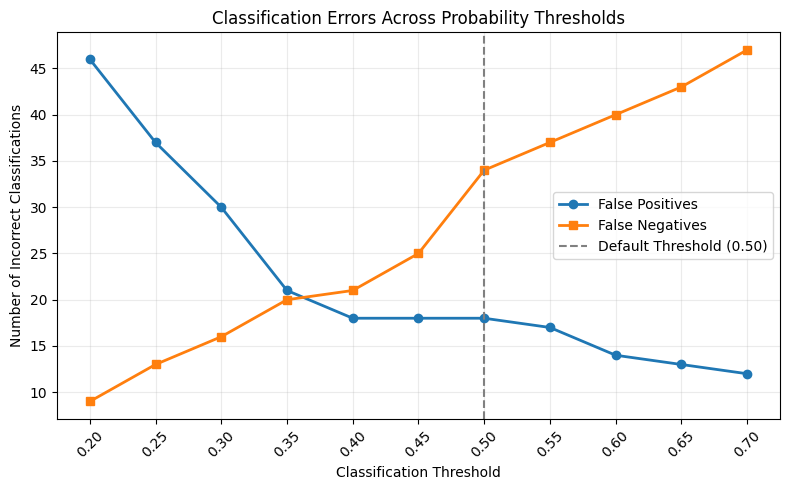

In [116]:
# Visualize the classification errors across different thresholds.
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_comparison["Threshold"],
    threshold_comparison["False Positives"],
    marker="o",
    linewidth=2,
    label="False Positives"
)

plt.plot(
    threshold_comparison["Threshold"],
    threshold_comparison["False Negatives"],
    marker="s",
    linewidth=2,
    label="False Negatives"
)

# Identify the default classification threshold.
plt.axvline(
    x=0.50,
    color="gray",
    linestyle="--",
    label="Default Threshold (0.50)"
)

plt.title("Classification Errors Across Probability Thresholds")
plt.xlabel("Classification Threshold")
plt.ylabel("Number of Incorrect Classifications")
plt.xticks(threshold_comparison["Threshold"], rotation=45)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 9.3 Comparing the Threshold Results with Naive Bayes

Having examined the alternative thresholds, we can now identify the configurations achieving the highest F1-score and spam recall, subsequently comparing their performance against the original Naive Bayes classifier.

In [117]:
# Identify the threshold with the highest F1-score.
best_f1_threshold = threshold_comparison.loc[
    threshold_comparison["F1-Score (%)"].idxmax()
]

# Identify the threshold with the highest spam recall.
best_recall_threshold = threshold_comparison.loc[
    threshold_comparison["Recall (%)"].idxmax()
]

# Display the leading threshold configurations.
leading_thresholds = pd.DataFrame([
    best_f1_threshold,
    best_recall_threshold
]).copy()

leading_thresholds.insert(
    0,
    "Selection Criterion",
    ["Highest F1-Score", "Highest Spam Recall"]
)

print("Leading Maximum Entropy threshold configurations:")
display(leading_thresholds.round(2))

# Display the original Naive Bayes results for comparison.
naive_bayes_reference = all_model_results[
    (all_model_results["Classifier"] == "Naive Bayes") &
    (all_model_results["Features"] == 57)
][[
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)",
    "False Positives",
    "False Negatives"
]]

print("\nOriginal 57-feature Naive Bayes performance:")
display(naive_bayes_reference.round(2))

Leading Maximum Entropy threshold configurations:


,Selection Criterion,Threshold,Accuracy (%),Precision (%),Recall (%),F1-Score (%),False Positives,False Negatives
4,Highest F1-Score,0.4,93.83,92.89,91.80,92.34,18.0,21.0
0,Highest Spam Recall,0.2,91.30,84.30,96.48,89.98,46.0,9.0



Original 57-feature Naive Bayes performance:


,Accuracy (%),Precision (%),Recall (%),F1-Score (%),False Positives,False Negatives
1,85.28,74.47,96.88,84.21,85,8


**Interpretation:**

The classification threshold analysis revealed that adjusting Maximum Entropy's default threshold substantially influenced its performance. At a threshold of 0.40, the classifier achieved its highest accuracy (93.83%) and F1-score (92.34%), whilst reducing false negatives from 34 to 21 without increasing false positives. This indicates that the adjustment improved spam detection without compromising the classification of legitimate emails within the development-test subset.

Furthermore, reducing the threshold to 0.20 increased spam recall to 96.48%, closely approaching the 96.88% achieved by Naive Bayes. However, Maximum Entropy recorded only 46 false positives at this threshold, compared with 85 for Naive Bayes. These findings suggest that adjusting the classification threshold can provide a more favorable balance between identifying spam and preserving legitimate correspondence. Consequently, the 0.40 threshold appears to provide the most favorable balance between accuracy and spam detection, whilst 0.20 remains a suitable alternative when maximizing spam recall is prioritized.

## 10. Final Model Evaluation

Having compared the classification approaches and examined the effects of adjusting their probability thresholds, the 57-feature Maximum Entropy classifier with a threshold of 0.40 was selected for final evaluation. This configuration achieved the highest development-test accuracy and F1-score amongst the threshold settings examined, whilst offering an improved balance between spam detection and the incorrect classification of legitimate emails.

To assess its performance on previously unseen observations, the selected classifier will be retrained using the combined training and development-test subsets. The previously reserved final test subset will then be used to evaluate its classification performance independently, without making further adjustments to the model configuration or classification threshold.

### 10.1 Retraining the Selected Classifier

Combining the training and development-test observations provides the selected classifier with additional examples from which to learn, whilst preserving the final test subset for independent evaluation.

In [118]:
# Combine the training and development-test subsets.
X_final_train = pd.concat([X_train, X_dev], axis=0)
y_final_train = pd.concat([y_train, y_dev], axis=0)

# Create a new instance of the selected Maximum Entropy classifier.
final_model = clone(models["Maximum Entropy"])

# Retrain the classifier using all available development observations.
final_model.fit(X_final_train, y_final_train)

# Preserve the selected classification threshold.
final_threshold = 0.40

print("Final classifier: Maximum Entropy")
print("Number of training observations:", len(X_final_train))
print("Number of predictor features:", X_final_train.shape[1])
print("Selected classification threshold:", final_threshold)
print("Final test observations:", len(X_test))

Final classifier: Maximum Entropy
Number of training observations: 3578
Number of predictor features: 57
Selected classification threshold: 0.4
Final test observations: 632


### 10.2 Evaluating Final Test Performance

With the model configuration finalized, we can now generate predictions for the unseen test observations and calculate the classification metrics.

In [119]:
# Obtain predicted spam probabilities for the final test subset.
spam_class_index = list(final_model.classes_).index(1)

final_probabilities = final_model.predict_proba(X_test)[
    :, spam_class_index
]

# Apply the selected classification threshold.
final_predictions = (
    final_probabilities >= final_threshold
).astype(int)

# Calculate final classification performance.
final_accuracy = accuracy_score(y_test, final_predictions)
final_precision = precision_score(
    y_test, final_predictions, zero_division=0
)
final_recall = recall_score(
    y_test, final_predictions, zero_division=0
)
final_f1 = f1_score(
    y_test, final_predictions, zero_division=0
)

# Calculate classification errors.
tn, fp, fn, tp = confusion_matrix(
    y_test, final_predictions, labels=[0, 1]
).ravel()

# Present the final results.
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)",
        "Correct Classifications",
        "Incorrect Classifications",
        "False Positives",
        "False Negatives"
    ],
    "Final Test Result": [
        final_accuracy * 100,
        final_precision * 100,
        final_recall * 100,
        final_f1 * 100,
        tp + tn,
        fp + fn,
        fp,
        fn
    ]
})

print("Final Test Classification Performance:")
display(final_results.round(2))

Final Test Classification Performance:


,Metric,Final Test Result
0,Accuracy (%),91.77
1,Precision (%),86.92
2,Recall (%),92.62
3,F1-Score (%),89.68
4,Correct Classifications,580.00
5,Incorrect Classifications,52.00
6,False Positives,34.00
7,False Negatives,18.00


### 10.3 Final Confusion Matrix

To examine the types of classification errors made by the selected model, a confusion matrix will now be generated using its final test predictions.

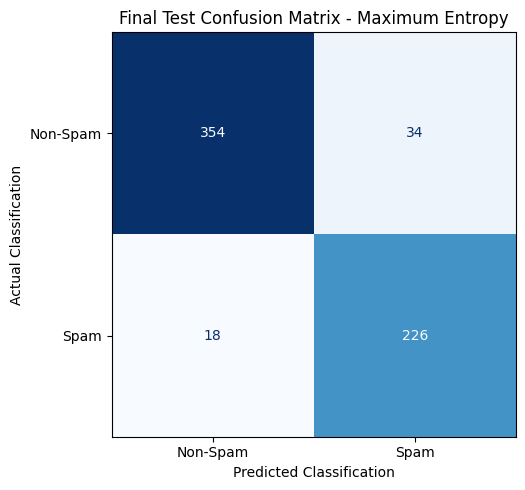

In [120]:
# Import the confusion matrix visualization.
from sklearn.metrics import ConfusionMatrixDisplay

# Generate the final test confusion matrix.
final_cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=[0, 1]
)

# Display the confusion matrix.
fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["Non-Spam", "Spam"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Final Test Confusion Matrix - Maximum Entropy")
plt.xlabel("Predicted Classification")
plt.ylabel("Actual Classification")
plt.tight_layout()
plt.show()

### 10.4 Comparing Development and Final Test Performance

Finally, we can now compare the selected model's development-test performance with its final test results. This will help establish whether the performance observed during threshold selection was reasonably consistent when evaluated using independent observations.

In [121]:
# Retrieve development-test results at the selected threshold.
development_results = threshold_comparison.loc[
    np.isclose(threshold_comparison["Threshold"], final_threshold)
].iloc[0]

# Compare development-test and final test performance.
performance_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ],
    "Development Test (%)": [
        development_results["Accuracy (%)"],
        development_results["Precision (%)"],
        development_results["Recall (%)"],
        development_results["F1-Score (%)"]
    ],
    "Final Test (%)": [
        final_accuracy * 100,
        final_precision * 100,
        final_recall * 100,
        final_f1 * 100
    ]
})

performance_comparison["Difference (pp)"] = (
    performance_comparison["Final Test (%)"]
    - performance_comparison["Development Test (%)"]
)

print("Development-Test and Final-Test Performance Comparison:")
display(performance_comparison.round(2))

Development-Test and Final-Test Performance Comparison:


,Metric,Development Test (%),Final Test (%),Difference (pp)
0,Accuracy (%),93.83,91.77,-2.06
1,Precision (%),92.89,86.92,-5.96
2,Recall (%),91.80,92.62,0.83
3,F1-Score (%),92.34,89.68,-2.66


**Interpretation:**

The final evaluation of the selected Maximum Entropy classifier, utilizing all 57 features and a classification threshold of 0.40, produced an accuracy of 91.77% and an F1-score of 89.68% across 632 previously unseen observations. Of these, 580 were correctly classified, comprising 354 non-spam and 226 spam emails. The model incorrectly identified 34 legitimate emails as spam, whilst overlooking 18 actual spam observations, resulting in a spam recall of 92.62%.

Compared with the development-test results, final accuracy decreased by 2.06 percentage points, whilst precision declined from 92.89% to 86.92%. However, spam recall increased slightly from 91.80% to 92.62%, suggesting that the classifier maintained its ability to identify a substantial proportion of spam observations. Although some variation was observed between the development and final test results, the findings indicate that the selected classifier maintained strong predictive performance on the independent test subset.

## 11. Conclusion and Limitations

This investigation evaluated the effectiveness of Decision Tree, Naive Bayes, and Maximum Entropy classifiers in distinguishing spam from non-spam emails using the UCI Spambase dataset. The analysis demonstrated that classification performance varied according to the algorithm, feature selection, and probability threshold utilized.

The principal findings were as follows:


*   **Model comparison**: Maximum Entropy achieved the highest development-test accuracy (91.77%) and F1-score (89.52%), whilst Naive Bayes recorded the highest spam recall (96.88%).
*   **Feature selection**: Reducing the number of predictors did not consistently improve performance, although the 10-feature Decision Tree demonstrated a modest improvement in accuracy.
*   **Threshold adjustment**: Lowering Maximum Entropy's classification threshold to 0.40 improved its development-test performance and provided a more favorable balance between spam detection and false positives.
*   **Final evaluation**: The selected Maximum Entropy classifier achieved 91.77% accuracy, 92.62% spam recall, and an F1-score of 89.68% across 632 previously unseen observations.

The study was limited by its reliance on a single dataset containing pre-extracted numerical features. Consequently, the computational requirements of extracting features from raw emails were not directly assessed, and the findings may not fully reflect contemporary spam characteristics. Despite these limitations, the results highlight the importance of considering classification errors alongside accuracy when developing effective spam-detection systems.





